# Pivot switching: KPP–Fisher (Fig. 3)

This example reproduces the paper's Fig. 3: plain Carleman diverges, and PSC with a switched
pivot follows the exact curve. The assembly exploits the ring's symmetry, which cuts the work to
102 `lin_ode` calls.

$$\frac{du_i}{dt}=u_{i-1}-2u_i+u_{i+1}+u_i(1-u_i),\qquad u_i=u_{i+8}$$

Eight sites on a ring, with $u_i(0)=0.9$ at $i=3,4$ and $0.1$ elsewhere.

Reproduces Fig. 3 of [arXiv:2411.16233](https://arxiv.org/abs/2411.16233); every equation number
here is that paper's, and this is its Eqs. (18)–(19).

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines Carleman, PSC, pivot, fold, bra, ket and
  the symbols $P$, $A$ and $\boldsymbol\Phi$.
- [`psc_carleman`](../tutorials/04_basis/psc_carleman.ipynb) constructs `PSCarlemanBasis`.
:::

| panel | run |
|---|---|
| (a) | the nonlinear ODE, integrated directly |
| (b) | Carleman, truncation order 3 |
| (c, d) | PSC at orders 3 and 5, pivot fixed at $s=1$ |
| (e, f) | the same, pivot switched from $u(0)$ to $1$ at $t=1$ |

> **Requires Linux or macOS and several cores.** The assembly hands one column per worker through a
> `fork`-based process pool, which Windows does not provide.


In [1]:
import itertools
import os
from collections import defaultdict
from concurrent.futures import ProcessPoolExecutor
from functools import cache, partial
from multiprocessing import get_context

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib import cm
from scipy.integrate import solve_ivp
from scipy.sparse import csc_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply

from lin_ode.basis import CarlemanBasis, PSCarlemanBasis, TruncatedBasisSet
from lin_ode import OperatorMatrix
from lin_ode.operators import Koopman
from lin_ode import OrdinaryDifferentialSystem

N, ORDER = 8, 2  # ring sites; on-site polynomial order M of the right-hand side, u(1 - u)
T_END, SWITCH, FRAMES = 5.0, 1.0, 501
WORKERS = os.cpu_count() or 4  # step 3 hands one column per worker
PROFILE = np.where(np.isin(np.arange(N), (3, 4)), 0.9, 0.1)  # u(t=0), Eq. (19)
PIVOT = sp.IndexedBase("s")  # per-site pivot; PIVOT[i] is the pivot at site i
FIXED_PIVOT = {k: 1.0 for k in range(N)}  # u = 1, the stable fixed point of u(1 - u)
INITIAL_PIVOT = {k: float(PROFILE[k]) for k in range(N)}  # s = u(0)
times = np.linspace(0, T_END, FRAMES)


def rhs(u: sp.IndexedBase, i: sp.Idx) -> sp.Expr:
    """Eq. (18), on a unit grid."""
    lap = u[sp.Mod(i - 1, N)] - 2 * u[i] + u[sp.Mod(i + 1, N)]
    return sp.expand(lap + u[i] * (1 - u[i]))


def rhs_numpy(u: np.ndarray) -> np.ndarray:
    """Eq. (18) on a whole profile."""
    return np.roll(u, 1) - 2 * u + np.roll(u, -1) + u * (1 - u)


print(f"f_i = {rhs(sp.IndexedBase('u'), sp.Idx('i', (0, N - 1)))}")
print(f"M = {ORDER}, so the generator raises a monomial by at most {ORDER - 1}")

StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors


f_i = u[Mod(i + 1, 8)] + u[Mod(i + 7, 8)] - u[i]**2 - u[i]
M = 2, so the generator raises a monomial by at most 1


## Assembly by shape

$\dim=\binom{13}{5}=1287$ at $P=5$, so $A$ holds 1.66M entries and `lin_ode` returns one per call.
Three steps cut that to 102 calls.

| step | function | what it saves |
| --- | --- | --- |
| 1 | `find_bras` | a column touches ~10 bras, not 1287 |
| 2 | `find_reference_ket` | kets of one *shape* share a column |
| 3 | `build_entries_by_shape` | one call per shape, relabelled onto the rest |

Then $\boldsymbol\Phi(t)=e^{At}\boldsymbol\Phi(0)$, one segment per pivot.

### 1. The sparsity pattern of a column

**Generator moves powers.** In $L=\sum_s f_s\partial_{u_s}$, each term of $f_s$ sends the ket to
exactly one monomial:

- on-site $u_s^r$: power at $s$ shifts by $r-1$
- diffusion: one power moves to $s\pm1$

**Truncation handles what goes above the degree.** `CarlemanBasis` drops that part.
`PSCarlemanBasis` folds it back (Eqs. 9 and 11). On one site:

$$u_i^{P+1}\longmapsto u_i^{P+1}-(u_i-s_i)^{P+1}$$

$s_i$ is the pivot at site $i$; the site index $s$ above and the pivot $s_i$ are different things,
and only the pivot carries a subscript from here on.

General monomial → its whole sub-monomial box:

$$y_m\;\longmapsto\;\sum_{\beta\le m,\;|\beta|\le P}T_{\beta m}(s)\,y_\beta$$

$$T_{\beta m}(s)=\Bigl(\prod_i s_i^{\,m_i-\beta_i}\Bigr)
\sum_{\substack{\beta\,\le\,j\,\le\,m\\ |j|\,\le\,P}}\ \prod_i(-1)^{\,j_i-\beta_i}
\binom{m_i}{j_i}\binom{j_i}{\beta_i}$$

$\beta\le m$ is componentwise, and $|\beta|$ is the total degree.

So the bras are the targets $\cup$ everything under them, which is what `find_bras` returns.
Skipping the box drops entries silently.


<!-- figure: psc-fold (docs/make_figures.py) -->

> **Example — the fold, on one site.**
>
> $$u^{P+1}\;\longmapsto\;-\sum_{m=0}^{P}\binom{P+1}{m}(-s)^{P+1-m}u^{m}$$
>
> ![The PSC fold: the weights it leaves on each retained basis state](../figures/psc-fold.png)
>
> A gold box holds the weight left on the state above it. This notebook's $M=2$ reaction reaches
> only $u^{P+1}$, the top row; $u^{P+2}$ needs the cubic term of
> [`psc_fig4_phase_field`](psc_fig4_phase_field.ipynb).
>
> At $s=0$ every weight vanishes. That is the drop, so Carleman is the $s=0$ case of PSC.


<!-- figure: psc-column (docs/make_figures.py) -->

> **Which elements are nonzero, and which repeat.**
>
> ![Where the fold applies, and how one call covers a whole shape](../figures/psc-column.png)
>
> **Left panel — one row per ket.** Each boxed number counts the nonzero entries in that ket's
> column: how many bras $m$ give $\langle m\rvert L_s\lvert\alpha\rangle\neq0$.
>
> | column | is |
> |---|---|
> | `deg` | the ket's total degree $\lvert\alpha\rvert$ |
> | `Carleman` | that count on `CarlemanBasis`, which **discards** targets above degree $P$ |
> | `PSC` | that count on `PSCarlemanBasis`, which **folds** those targets back onto in-basis bras |
> | `find_bras` | how long the list `find_bras` returns is |
> | red outline | `PSC` exceeds `Carleman`, so the fold applied on this row |
>
> - $\lvert u_0u_1\rangle$: degree $2<P$, so nothing goes above the degree and the two bases agree.
> - $\lvert u_0u_1^2\rangle$: degree $3=P$, so targets go above the degree and the fold lands
>   weight on further bras.
> - `find_bras` bounds the work; it does not predict the count.
>
> **Right panel — one ket of one shape.** A gold circle is an occupied site and its number is that
> site's power; grey circles are empty. The red bond joins the two occupied sites.
>
> Step 2's $2N=16$ relabellings send this ket to 16 distinct images, counted there.
>
> So the whole shape costs one `lin_ode` call. That 16 is unrelated to the 16 bras on the left.


In [2]:
def shift_powers(powers: dict[int, int], *moves: tuple[int, int]) -> StateLabel:
    """`powers` with each (site, delta) applied, back as a sorted (site, power) tuple."""
    moved = dict(powers)
    for site, delta in moves:
        moved[site] = moved.get(site, 0) + delta
    return tuple(sorted((site, power) for site, power in moved.items() if power > 0))


def find_reachable_monomials(ket: StateLabel) -> set[StateLabel]:
    """Monomials the generator can send `ket` to, before any truncation."""
    powers = {int(site): int(power) for site, power in ket}
    targets = {shift_powers(powers, (site, delta))
               for site in powers for delta in range(-1, ORDER)}
    targets |= {shift_powers(powers, (site, -1), ((site + step) % N, 1))
                for site in powers for step in (-1, 1)}
    return targets


def find_bras(ket: StateLabel, degree: int) -> list[StateLabel]:
    """Bras that can pick up weight from `ket`: each target, and everything a fold puts under it."""
    bras = set()
    for target in find_reachable_monomials(ket):
        for lowered in itertools.product(*(range(power + 1) for _, power in target)):
            if sum(lowered) <= degree:  # every sub-monomial of this target, in the basis
                bras.add(tuple((site, p) for (site, _), p in zip(target, lowered) if p > 0))
    return sorted(bras)

In [3]:
ket = ((0, 1), (1, 1))  # |u_0 u_1>
print(f"reaches {len(find_reachable_monomials(ket))} monomials")
print(f"folding onto {len(find_bras(ket, 3))} bras at P=3, out of {len(CarlemanBasis(N, 3))} states")
print("u_0^4 folds to:", sp.expand(PSCarlemanBasis(N, 3, PIVOT).truncation_rule((0, 4))))

reaches 9 monomials
folding onto 12 bras at P=3, out of 165 states
u_0^4 folds to: -CarlemanState()*s[0]**4 + 4*s[0]**3*CarlemanState((0, 1)) - 6*s[0]**2*CarlemanState((0, 2)) + 4*s[0]*CarlemanState((0, 3))


### 2. Shape classes under the ring symmetry

Relabel the sites, using $N$ offsets and 2 signs, so $2N$ maps:

$$\sigma_{a,\pm}(i)=(a\pm i)\bmod N,\qquad \tilde u_i\equiv u_{\sigma(i)}$$

The equation is unchanged by it (neighbour sum + on-site reaction $R(u)=u(1-u)$):

$$\frac{d\tilde u_i}{dt}=\frac{du_{\sigma(i)}}{dt}
=u_{\sigma(i)-1}+u_{\sigma(i)+1}-2u_{\sigma(i)}+R\bigl(u_{\sigma(i)}\bigr)
=\tilde u_{i-1}+\tilde u_{i+1}-2\tilde u_i+R(\tilde u_i)$$

- $\{\sigma(i)-1,\sigma(i)+1\}=\{\sigma(i-1),\sigma(i+1)\}$: rotations keep the order and
  reflections swap it, and the sum covers both
- $R$ depends on one site

A ket is a list of (site, power) pairs, and $\sigma$ relabels the sites and leaves the powers
unchanged:

$$\sigma\bigl((i_1,p_1),\dots,(i_k,p_k)\bigr)=\bigl((\sigma(i_1),p_1),\dots,(\sigma(i_k),p_k)\bigr)
\qquad\sigma(i)=i{+}3:\;|u_0u_1\rangle\mapsto|u_3u_4\rangle$$

The pivot list $s=(s_0,\dots,s_{N-1})$ is indexed by site too, so $\sigma$ applies to it as well:

$$\langle\,\sigma(m)\,|\,L_{\sigma(s)}\,|\,\sigma(\alpha)\,\rangle=\langle m|L_s|\alpha\rangle$$

**Shape** = kets related by some $\sigma$:

- $|u_0u_1\rangle$, $|u_3u_4\rangle$, $|u_7u_0\rangle$ are one shape, "two adjacent sites, power 1"
- the **reference ket** is a shape's least image, one per shape


In [4]:
def find_reference_ket(ket: StateLabel) -> tuple[StateLabel, dict[int, int]]:
    """The one ket standing for `ket`'s shape, and the site map from it back to `ket`."""

    def image(relabel: tuple[int, int]) -> StateLabel:
        offset, sign = relabel
        return tuple(sorted(((offset + sign * int(s)) % N, int(p)) for s, p in ket))

    relabels = [(offset, sign) for offset in range(N) for sign in (1, -1)]  # sigma(i) = offset + sign*i
    offset, sign = min(relabels, key=image)          # least image: arbitrary but fixed
    back = {(offset + sign * site) % N: site for site in range(N)}  # sigma read backwards
    return image((offset, sign)), back

In [5]:
demo_basis = CarlemanBasis(N, 3)
shapes: defaultdict[StateLabel, list[StateLabel]] = defaultdict(list)
for flat in range(len(demo_basis)):
    ket = demo_basis.structured_idx_of_flat_index(flat)
    if ket:  # the vacuum is its own trivial case
        reference, _ = find_reference_ket(ket)
        shapes[reference].append(ket)

print(f"{len(demo_basis) - 1} kets share {len(shapes)} shapes, for instance")
for reference in (((0, 1),), ((0, 1), (1, 1)), ((0, 1), (3, 2))):
    print(f"   {str(reference):20s} <- {len(shapes[reference])} kets: {shapes[reference][:3]} ...")

164 kets share 16 shapes, for instance
   ((0, 1),)            <- 8 kets: [((0, 1),), ((1, 1),), ((2, 1),)] ...
   ((0, 1), (1, 1))     <- 8 kets: [((0, 1), (1, 1)), ((0, 1), (7, 1)), ((1, 1), (2, 1))] ...
   ((0, 1), (3, 2))     <- 16 kets: [((0, 2), (3, 1)), ((0, 2), (5, 1)), ((0, 1), (3, 2))] ...


### 3. One `lin_ode` call per shape

One call returns a whole column, meaning every bra a given ket can reach:

$$C_{\alpha}(m)=\langle m\rvert L_s\lvert\alpha\rangle,\qquad m\in\mathcal B(\alpha)$$

$\mathcal B(\alpha)$ is the bra list `find_bras` builds, and $L_s$ carries the pivot list
$s=(s_0,\dots,s_{N-1})$ from step 2.

Every other ket of the same shape is $\alpha=\tau(\alpha_0)$ for the reference $\alpha_0$, with
$\tau=\sigma^{-1}$, the `back` map. Its column costs no algebra, only a relabelling:

$$\bigl\langle \tau(m)\bigr\rvert L_s\bigl\lvert \tau(\alpha_0)\bigr\rangle
=\Bigl[\;\langle m\rvert L_s\lvert\alpha_0\rangle\;\Bigr]_{\,s_j\,\to\,s_{\tau(j)}}$$

**Worked, at $P=3$ on the $N=8$ ring.**

| | |
|---|---|
| reference ket $\alpha_0$ | $\lvert u_0u_1u_3\rangle$ |
| target ket $\tau(\alpha_0)$ | $\lvert u_0u_1u_6\rangle$ |
| the `back` map $\tau$ | $0\mapsto1,\quad 1\mapsto0,\quad 3\mapsto6$ |

Take one entry of that column, a bra the fold has put a pivot into:

| | bra | value |
|---|---|---|
| in the reference column | $\langle u_0u_1\rvert$ | $2s_0s_3+2s_1s_3+s_3^{2}$ |
| after `relabel_column` | $\langle u_0u_1\rvert$, **unmoved** | $2s_0s_6+2s_1s_6+s_6^{2}$ |

Two substitutions run independently:

| what moves | rule | here |
|---|---|---|
| the bra's sites | $j\mapsto\tau(j)$ | $u_0u_1\mapsto u_1u_0$, the same monomial |
| the pivot symbols | $s_j\mapsto s_{\tau(j)}$ | $s_3\mapsto s_6$ |

**This entry is why the pivots must travel.** $\tau$ swaps sites $0$ and $1$, and $u_0u_1$ is
symmetric under that swap, so the bra does not move at all.

Move only the bras and the entry stays exactly as it was, still carrying a pivot on site $3$. The
ket $\lvert u_0u_1u_6\rangle$ never touches site $3$.

A uniform pivot would not notice. A per-site one is silently wrong.



**Then `build_matrix`:** substitute $s_j\to$ float, cast, and transpose, because `lin_ode` indexes
bra-first:

$$\dot y_\alpha=\sum_m\langle m\rvert L_s\lvert\alpha\rangle\,y_m
\qquad\Longrightarrow\qquad A_{\alpha m}=\langle m\rvert L_s\lvert\alpha\rangle$$


In [6]:
@cache  # one operator per basis, per process
def get_koopman_matrix(basis: TruncatedBasisSet) -> OperatorMatrix:
    """`lin_ode`'s symbolic <bra| L |ket> for Eq. (18) on `basis`."""
    u, i = sp.IndexedBase("u"), sp.Idx("i", (0, N - 1))
    ode = OrdinaryDifferentialSystem.from_sympy(rhs(u, i), u, (i,))
    return OperatorMatrix(basis, Koopman().create_operator(ode))


def compute_column(
    basis: TruncatedBasisSet, ket: StateLabel
) -> dict[StateLabel, sp.Expr]:
    """{bra: value} for one ket -- the pool's unit of work."""
    bras = find_bras(ket, basis.degree)
    column = get_koopman_matrix(basis)[bras, [ket]]
    return {bra: column[row, 0] for row, bra in enumerate(bras) if column[row, 0] != 0}


def map_columns(
    basis: TruncatedBasisSet, kets: list[StateLabel]
) -> list[dict[StateLabel, sp.Expr]]:
    """One column per worker; needs `fork`, since a spawned child cannot import a notebook."""
    with ProcessPoolExecutor(WORKERS, mp_context=get_context("fork")) as pool:
        return list(pool.map(partial(compute_column, basis), kets, chunksize=1))


def relabel_column(
    column: dict[StateLabel, sp.Expr], back: dict[int, int]
) -> dict[StateLabel, sp.Expr]:
    """A reference column moved onto a shape-mate: `s[i]` labels a site, so it travels too."""
    pivots = {PIVOT[site]: PIVOT[image] for site, image in back.items()}
    moved = {}
    for bra, value in column.items():
        moved[tuple(sorted((back[s], p) for s, p in bra))] = sp.sympify(value).xreplace(pivots)
    return moved


def build_entries_by_shape(
    basis: TruncatedBasisSet,
) -> tuple[dict[tuple[int, int], sp.Expr], int]:
    """Symbolic {(bra, ket): value} for the whole basis, and how many columns it cost."""
    kets = [basis.structured_idx_of_flat_index(k) for k in range(len(basis))]
    shape_of = {ket: find_reference_ket(ket) for ket in kets if ket}  # ket -> (reference, back)
    references = list(dict.fromkeys(reference for reference, _ in shape_of.values()))
    columns = dict(zip(references, map_columns(basis, references)))

    entries: dict[tuple[int, int], sp.Expr] = {}
    for ket_flat, ket in enumerate(kets):
        if not ket:
            continue  # every term carries a d/du_s, so the vacuum column is zero
        reference, back = shape_of[ket]
        for bra, value in relabel_column(columns[reference], back).items():
            entries[(basis.flat_index_of_structured_index(bra), ket_flat)] = value
    return entries, len(references)


def build_matrix(
    entries: dict[tuple[int, int], sp.Expr],
    dim: int,
    pivot: dict[int, float] = {},  # noqa: B006 - read-only
) -> csc_matrix:
    """A for dPhi/dt = A Phi; transposed because lin_ode indexes bra-first."""
    subs = {PIVOT[k]: sp.Float(v) for k, v in pivot.items()}
    rows = [row for row, _ in entries]
    cols = [col for _, col in entries]
    data = [float(sp.sympify(value).xreplace(subs)) for value in entries.values()]
    return csr_matrix((data, (rows, cols)), shape=(dim, dim)).T.tocsc()

---

> **Check — relabelling is exact**, not a step of the method. A column moved from its reference must
> equal one computed from scratch, pivot symbols included.


In [7]:
check_basis = PSCarlemanBasis(N, 3, PIVOT)
check_ket = ((3, 1), (4, 1))
reference, back = find_reference_ket(check_ket)

moved = relabel_column(compute_column(check_basis, reference), back)
direct = compute_column(check_basis, check_ket)
assert moved.keys() == direct.keys(), "relabelling landed on different bras"
assert all(sp.simplify(moved[bra] - direct[bra]) == 0 for bra in direct), "values disagree"
print(f"column of {check_ket} reproduced by relabelling its reference {reference}")

column of ((3, 1), (4, 1)) reproduced by relabelling its reference ((0, 1), (1, 1))


## Assembling the Carleman and PSC generators

One assembly per basis; the pivot stays symbolic, so one assembly serves both pivots.

⚠️ **A couple of minutes** on 10 cores, almost all of it the $P=5$ PSC assembly. The process pool
in step 3 is what keeps that time down.

In [8]:
carleman_basis = CarlemanBasis(N, 3)  # the paper compares against K = 3 only
carleman_entries, columns = build_entries_by_shape(carleman_basis)
carleman_matrix = build_matrix(carleman_entries, len(carleman_basis))
print(f"Carleman K=3: dim={len(carleman_basis)} nnz={carleman_matrix.nnz} "
      f"from {columns} lin_ode columns")

psc_bases = {p: PSCarlemanBasis(N, p, PIVOT) for p in (3, 5)}
psc_entries = {}
for p, basis in psc_bases.items():
    psc_entries[p], columns = build_entries_by_shape(basis)
    print(f"PSC P={p}: dim={len(basis)} entries={len(psc_entries[p])} "
          f"from {columns} lin_ode columns")


def psc_matrix(p: int, pivot: dict[int, float]) -> csc_matrix:
    """A at degree `p` about `pivot` -- a substitution; the symbolic work is already done."""
    return build_matrix(psc_entries[p], len(psc_bases[p]), pivot)


# label -> (basis, segments); a second segment switches the pivot at t = SWITCH
runs = {
    "Carleman K=3": (carleman_basis, [(T_END, carleman_matrix)]),
    "PSC P=3, s=1": (psc_bases[3], [(T_END, psc_matrix(3, FIXED_PIVOT))]),
    "PSC P=5, s=1": (psc_bases[5], [(T_END, psc_matrix(5, FIXED_PIVOT))]),
    "PSC P=3, switched": (psc_bases[3], [(SWITCH, psc_matrix(3, INITIAL_PIVOT)),
                                         (T_END, psc_matrix(3, FIXED_PIVOT))]),
    "PSC P=5, switched": (psc_bases[5], [(SWITCH, psc_matrix(5, INITIAL_PIVOT)),
                                         (T_END, psc_matrix(5, FIXED_PIVOT))]),
}
for label, (basis, segments) in runs.items():
    print(f"{label:20s} dim={len(basis):5d}  nnz={segments[-1][1].nnz:6d}  "
          f"{len(segments)} segment(s)")

Carleman K=3: dim=165 nnz=956 from 16 lin_ode columns


PSC P=3: dim=165 entries=2196 from 16 lin_ode columns


PSC P=5: dim=1287 entries=45158 from 102 lin_ode columns


Carleman K=3         dim=  165  nnz=   956  1 segment(s)
PSC P=3, s=1         dim=  165  nnz=  2196  1 segment(s)
PSC P=5, s=1         dim= 1287  nnz= 45158  1 segment(s)
PSC P=3, switched    dim=  165  nnz=  2196  2 segment(s)
PSC P=5, switched    dim= 1287  nnz= 45158  2 segment(s)


## Segment-wise propagation

$$\boldsymbol\Phi(t)=e^{At}\boldsymbol\Phi(0)$$

- one `expm_multiply` per segment, nothing to tune
- a pivot switch only changes the matrix of the next segment, and $\boldsymbol\Phi$ crosses the
  switch unchanged

In [9]:
def evolve(segments: list[tuple[float, csc_matrix]], initial: np.ndarray) -> np.ndarray:
    """Phi(t) on `times`, exponentiating each (t_to, A) segment in turn."""
    vector, t_from, blocks = initial, 0.0, [initial[None, :]]
    for t_to, matrix in segments:
        num = 1 + round((t_to - t_from) / T_END * (FRAMES - 1))
        block = expm_multiply(matrix, vector, start=0, stop=t_to - t_from, num=num, endpoint=True)
        blocks.append(block[1:])  # [1:]: t_from is already in
        vector, t_from = block[-1], t_to
    return np.concatenate(blocks)


def solve(basis: TruncatedBasisSet, segments: list[tuple[float, csc_matrix]]) -> np.ndarray:
    """u_i(t): evaluate every monomial at the profile, evolve, slice the degree-1 rows out."""
    monomials = [basis.structured_idx_of_flat_index(k) for k in range(len(basis))]
    initial = np.array([np.prod([PROFILE[int(s)] ** int(p) for s, p in m]) for m in monomials])
    rows = [basis.flat_index_of_basis_function(basis.state_type((k, 1))) for k in range(N)]
    trajectory = evolve(segments, initial)[:, rows]  # u_i *is* a basis element, so it is a slice
    assert len(trajectory) == FRAMES, "segment grids do not add up to the time grid"
    return trajectory


solutions = {label: solve(basis, segments) for label, (basis, segments) in runs.items()}
print(f"{len(solutions)} linear solutions, {FRAMES} frames each")

5 linear solutions, 501 frames each


## Direct nonlinear reference

The nonlinear ODE integrated directly. The reference shares no code with the linearization, so an
agreement is not two implementations of one idea agreeing with each other.

In [10]:
nonlinear = solve_ivp(
    lambda _, u: rhs_numpy(u), (0.0, T_END), PROFILE, t_eval=times,
    method="LSODA", rtol=1e-10, atol=1e-12,
)
assert nonlinear.success, nonlinear.message
classical = nonlinear.y.T
solutions = {"classical": classical} | solutions

for label, trajectory in solutions.items():
    print(f"{label:20s} max|u| = {np.abs(trajectory).max():10.4g}   "
          f"u(5) = {trajectory[-1].mean():10.4f}   "
          f"max deviation from classical = {np.abs(trajectory - classical).max():.4g}")

classical            max|u| =     0.9805   u(5) =     0.9789   max deviation from classical = 0
Carleman K=3         max|u| =  1.049e+05   u(5) = 88779.7215   max deviation from classical = 1.049e+05
PSC P=3, s=1         max|u| =     0.9894   u(5) =     0.9890   max deviation from classical = 0.1666
PSC P=5, s=1         max|u| =      0.986   u(5) =     0.9852   max deviation from classical = 0.08289
PSC P=3, switched    max|u| =     0.9837   u(5) =     0.9827   max deviation from classical = 0.03321
PSC P=5, switched    max|u| =     0.9815   u(5) =     0.9801   max deviation from classical = 0.007967


## Six-panel comparison with the paper

One line per sampled time, coloured by $t$; black is $t=0$. Panels read down the columns, as in the
paper.

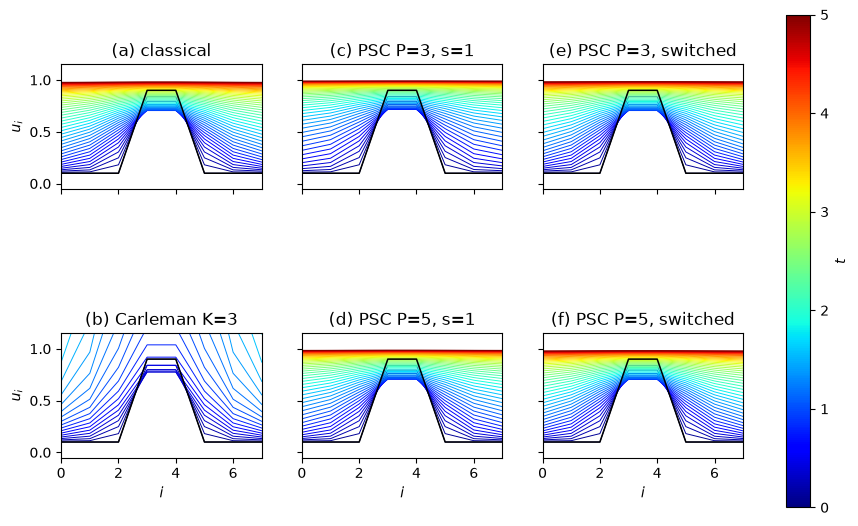

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharex=True, sharey=True)
for letter, ax, (label, trajectory) in zip("abcdef", axes.T.ravel(), solutions.items()):
    for k in range(0, FRAMES, 10):  # one line per sampled time, coloured by t
        ax.plot(range(N), trajectory[k], color=cm.jet(times[k] / T_END), lw=0.7)
    ax.plot(range(N), trajectory[0], "k-", lw=1.1)  # black is t = 0
    ax.set(title=f"({letter}) {label}", xlim=(0, N - 1), ylim=(-0.05, 1.15))
    ax.set_box_aspect(0.62)
for row in (0, 1):
    axes[row, 0].set_ylabel("$u_i$")
for col in range(3):
    axes[1, col].set_xlabel("$i$")
fig.colorbar(cm.ScalarMappable(cmap=cm.jet, norm=plt.Normalize(0, T_END)),
             ax=axes, label="$t$")
plt.show()

| panel | what it shows |
|---|---|
| **(b)** | Carleman $K=3$ leaves the axes: the truncated solution has departed from the exact one |
| **(c, d)** | pivot fixed at $s=1$: bounded, but biased early |
| **(e, f)** | pivot switched at $t=1$: follows the exact curve |

---

[← KPP–Fisher, position-dependent](kpp_fisher_position_dependent_1d.ipynb) · [Notebook index](../README.md) · [Pivot switching: phase field →](psc_fig4_phase_field.ipynb)